# Commitment sweep — what is the locked prefix costing us?

`reordering-headroom.ipynb` found that **16% of served riders board without the
policy ever having scheduled them**: 14.8 `_adopt_dropoff` calls per 100 plan
calls. It also refuted the explanation offered for that at the time. The claim
was that these are riders the policy *rejected*, boarded anyway by
`BusAgent._board`. The no-window control rejects nobody and still posts 13.1
adoptions per 100, so rejection can account for at most ~11% of them.

Something else is producing the other ~89%, and there are two candidate paths.
This notebook separates them by sweeping `commitment`.

## The two paths

**Path A — boarded at the current stop, before the replan.** `on_arrival`
alights, boards, *then* re-plans (`BusAgent.on_arrival`). A request created
during the leg into stop *S*, with its pickup at *S*, is boarded the moment the
bus arrives and is already `ON_BUS` by the time the policy next sees the world.
The policy never had a chance to schedule it.

**This path is independent of `commitment`** — boarding at the current stop
always precedes `_replan`, whatever the prefix length.

**Path B — pre-boarded by the projection.** `_build_projected_state` walks the
committed prefix and boards pending requests at each committed stop, adding
them to `sim_boarded_ids`. Those requests are then excluded from `sim_pending`:

```python
sim_pending = [
    r for r in self._pool.get_pending()
    if r.id not in sim_boarded_ids
]
```

So a pending request whose pickup falls inside the committed prefix is handed
to the policy as **already aboard**. It never appears in `pending_requests`,
never reaches `_new_requests`, and can never be inserted — its dropoff must be
adopted instead.

**This path scales with `commitment`, and vanishes entirely at
`commitment=0`**, where the projection loop does not execute at all.

That makes the sweep a clean decomposition: the adoption rate at
`commitment=0` is Path A alone, and everything above that line is Path B.

## The questions, and what would settle them

### Q1 — is adoption commitment-driven?

- **Rate rises with `commitment`, and `commitment=0` is visibly lowest** →
  Path B is real and the default of 2 is manufacturing forced adoptions. The
  height above the `commitment=0` line measures exactly how many.
- **Rate flat across all five levels** → Path B contributes nothing, adoption
  is entirely Path A, and it is a fixed cost of the arrival-then-replan
  ordering rather than anything tunable. The "forced splice" strand of the
  reordering argument would then be architecture, not a knob.
- **Rate *falls* as commitment rises** → neither story is right and the
  mechanism needs rethinking from scratch.

The stacked split is a secondary check: the "offered as PENDING earlier"
segment is the rejection-attributable share and should stay small and roughly
flat (~11% of adoptions, per the headroom run). Any commitment effect belongs
in the "never offered" segment.

### Q2 — does `commitment` cost anything measurable?

Independent of Q1, and the reason this is worth running even if Q1 comes back
flat.

- **Served fraction falls as commitment rises** → the default of 2 is costing
  coverage, and lowering it is a free win requiring no new code at all.
- **Flat** → commitment is KPI-neutral on this map and can be chosen on other
  grounds. CARLA will want it non-zero regardless: a real vehicle cannot
  re-plan the stop it is already braking for.
- **`commitment=0` is worse** → the locked prefix is doing useful work, most
  likely by keeping the projected clock honest, and should be left alone.

Watch mean and max ride alongside served fraction. A longer committed prefix
means planning from a staler projection, so if anything degrades quietly it
will be ride quality.

### A note for the reordering work

A locked prefix is off-limits to any future reorder step, so this sweep also
puts a number on how much of a median-13-request schedule an L1 pass could
actually touch.

In [1]:
%matplotlib inline
# Static comparison charts only, so the inline backend is all we need.

import statistics
import time
from collections import defaultdict
from dataclasses import dataclass, field
from typing import Callable

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src.algorithm.DispatchPolicy import BusState
from src.algorithm.RequestPool import Request
from src.algorithm.Schedule import Schedule
from src.algorithm.WindowInsertionPolicy import WindowInsertionPolicy
from src.experiment import (
    ComparisonSummary,
    run_trial,
    summarize_comparison,
)
from src.map.PlanarMapProvider import PlanarMapProvider
from src.map.TransitGraph import TransitGraph
from src.map.graph import PlanarStreetGraph


@dataclass
class Tally:
    """
    Counters accumulated over every trial at one commitment level.

    :param plan_calls: Completed calls to ``plan``.
    :param adoptions: Calls to ``_adopt_dropoff``.
    :param adoptions_unseen: Adoptions of a request that had never been
        offered to the policy as PENDING on any earlier plan call — Path A
        and Path B both land here, which is why the sweep rather than this
        split is what separates them.
    :param insertion_attempts: Calls to ``_best_insertion``.
    :param rejections: Attempts that found no feasible slot pair.
    :param owner_counts: Distinct requests in the schedule, one sample per
        plan call. Included so the reorderable set can be compared against
        the committed prefix that would be off-limits to it.
    """

    plan_calls: int = 0
    adoptions: int = 0
    adoptions_unseen: int = 0
    insertion_attempts: int = 0
    rejections: int = 0
    owner_counts: list[int] = field(default_factory=list)


# Keyed by column label. The sweep cell clears this first, so re-executing it
# replaces the tallies rather than adding to them.
STATS: dict[str, Tally] = defaultdict(Tally)


class InstrumentedPolicy(WindowInsertionPolicy):
    """
    WindowInsertionPolicy that records forced dropoff adoptions.

    Behaviourally identical to its parent: every override counts, then
    delegates straight up. Same pattern as ``reordering-headroom.ipynb``,
    with one addition — a per-policy record of which requests have ever been
    offered as PENDING, so an adoption can be attributed to the rejection
    path or not.
    """

    def __init__(
        self,
        graph: TransitGraph,
        label: str,
        max_wait_s: float,
        **kwargs: float,
    ) -> None:
        """
        :param graph: Transit graph, forwarded to the parent.
        :param label: Column label these counts are filed under.
        :param max_wait_s: Service window in seconds.
        :param kwargs: Any other WindowInsertionPolicy argument.
        """
        super().__init__(graph, max_wait_s=max_wait_s, **kwargs)
        self._label = label
        self._seen_pending: set[str] = set()

    def plan(self, state: BusState, n_stops: int) -> list[str]:
        """Plan normally, then record what this call was offered."""
        route = super().plan(state, n_stops)

        tally = STATS[self._label]
        tally.plan_calls += 1
        tally.owner_counts.append(len(self.schedule.owners()))

        # Updated *after* the parent runs, so while an adoption is being
        # counted inside super().plan(), _seen_pending still reflects only
        # what earlier calls were offered. "Seen" therefore means "seen
        # before now", which is the question being asked.
        self._seen_pending.update(
            request.id for request in state.pending_requests
        )
        return route

    def _adopt_dropoff(
        self, schedule: Schedule, request: Request, state: BusState
    ) -> Schedule:
        """Count the forced adoption, then adopt normally."""
        tally = STATS[self._label]
        tally.adoptions += 1
        if request.id not in self._seen_pending:
            tally.adoptions_unseen += 1
        return super()._adopt_dropoff(schedule, request, state)

    def _best_insertion(
        self, schedule: Schedule, request: Request, state: BusState
    ) -> Schedule | None:
        """Insert normally, then record whether the request was rejected."""
        result = super()._best_insertion(schedule, request, state)
        tally = STATS[self._label]
        tally.insertion_attempts += 1
        if result is None:
            tally.rejections += 1
        return result


def make_factory(
    label: str, window: float
) -> Callable[[TransitGraph], InstrumentedPolicy]:
    """
    Build a policy factory bound to one label and one service window.

    A named closure rather than a lambda, so the late-binding trap that bites
    list comprehensions cannot arise.
    :param label: Column label the counts are filed under.
    :param window: Service window in seconds.
    :return: Callable taking a TransitGraph and returning a policy.
    """
    def factory(graph: TransitGraph) -> InstrumentedPolicy:
        return InstrumentedPolicy(graph, label=label, max_wait_s=window)
    return factory

## 1. Shared map

Identical to every previous sweep — same `MAP_SEED`, same campus configuration
— so `commitment=2` below is directly comparable to the `W900 / 200 req`
column in `reordering-headroom.ipynb`.

In [2]:
MAP_SEED = 42

graph = PlanarStreetGraph.generate(
    n_seeds=17,
    bounds=(0.0, 0.0, 2000.0, 2000.0),
    seed=MAP_SEED,
    stop_density=0.5,
)

provider = PlanarMapProvider(graph)
print(f"{len(provider.get_stops())} bus stops on this map")

21 bus stops on this map


## 2. Cost check

`commitment=8` projects eight stops forward on every re-plan, which is four
times the work the default does and has never been run. One trial is timed at
each end of the sweep before committing to the whole thing.

The probe files its tallies under a throwaway label and pops only that key, so
this cell is safe to run in any order.

In [3]:
N_TRIALS = 20
BASE_SEED = 0
COMMITMENTS = [0, 1, 2, 4, 8]

# The policy's service window. Matches the abandonment threshold below, which
# reordering-headroom.ipynb established as the best operating point.
WINDOW_S = 900.0

# run_trial kwargs. NOTE: max_wait_s here is the *backend's abandonment
# threshold*, a different quantity from the policy's service window above;
# they coincide at 900s deliberately.
LOAD = dict(max_requests=200, capacity=40, max_wait_s=900.0)

PROBE_LABEL = "timing probe"
probe_costs: dict[int, float] = {}

for probe_commitment in (COMMITMENTS[0], COMMITMENTS[-1]):
    start = time.perf_counter()
    run_trial(
        policy_factory=make_factory(PROBE_LABEL, WINDOW_S),
        graph=graph,
        seed=BASE_SEED,
        silent=True,
        commitment=probe_commitment,
        **LOAD,
    )
    probe_costs[probe_commitment] = time.perf_counter() - start

STATS.pop(PROBE_LABEL, None)

mean_cost = statistics.fmean(probe_costs.values())
projected_s = N_TRIALS * len(COMMITMENTS) * mean_cost
display(Markdown("\n".join(
    [f"- One trial at **commitment={commitment}**: {cost:.1f} s"
     for commitment, cost in probe_costs.items()]
    + [f"\nProjected total for the sweep below "
       f"({N_TRIALS} trials x {len(COMMITMENTS)} levels): "
       f"**{projected_s / 60:.1f} min**"]
)))

- One trial at **commitment=0**: 1.2 s
- One trial at **commitment=8**: 0.1 s

Projected total for the sweep below (20 trials x 5 levels): **1.1 min**

## 3. The sweep

Five levels, 20 trials each, everything else held at the headroom notebook's
configuration. `commitment` is a `run_trial` argument rather than a policy
argument, and `summarize_comparison` forwards one set of trial kwargs to every
column it is handed, so each level needs its own call.

**Built-in regression check:** `commitment=2` is the same map, seeds, load and
window as `W900 / 200 req` in `reordering-headroom.ipynb`. It should reproduce
that column exactly — 3,862 plan calls, 14.8 adoptions per 100, 91.3% served.
If it does not, something is less reproducible than we believed, and that
matters more than either question this notebook asks.

In [4]:
def commitment_label(commitment: int) -> str:
    """
    Column label for one commitment level.
    :param commitment: Number of leading stops locked during re-planning.
    :return: The label STATS and the summaries are keyed by.
    """
    return f"commitment={commitment}"


# Cleared first so re-executing this cell replaces the tallies.
STATS.clear()

summaries: dict[int, ComparisonSummary] = {}
for commitment in COMMITMENTS:
    label = commitment_label(commitment)
    summaries[commitment] = summarize_comparison(
        policies=[(label, make_factory(label, WINDOW_S))],
        graph=graph,
        n_trials=N_TRIALS,
        base_seed=BASE_SEED,
        commitment=commitment,
        **LOAD,
    )

commitment=0:   0%|          | 0/20 [00:00<?, ?it/s]

commitment=1:   0%|          | 0/20 [00:00<?, ?it/s]

commitment=2:   0%|          | 0/20 [00:00<?, ?it/s]

commitment=4:   0%|          | 0/20 [00:00<?, ?it/s]

commitment=8:   0%|          | 0/20 [00:00<?, ?it/s]

## 4. The mechanism table

The bold row is Q1. Read it against the `commitment=0` column, which is Path A
with Path B switched off by construction.

In [5]:
def per_100(numerator: int, denominator: int) -> float:
    """
    Rate per 100 opportunities, degrading to NaN rather than raising.
    :param numerator: Count of events.
    :param denominator: Count of opportunities.
    :return: Events per 100 opportunities, or NaN when denominator is zero.
    """
    if denominator == 0:
        return float("nan")
    return 100.0 * numerator / denominator


def median_of(values: list[int]) -> float:
    """
    Median of a list of counts, or NaN when there are no samples.
    :param values: Sampled counts, in any order.
    :return: The median, or NaN.
    """
    return statistics.median(values) if values else float("nan")


def seen_adoptions(tally: Tally) -> int:
    """
    Adoptions of a request the policy had already been offered as PENDING.

    These are the rejection-attributable ones: the policy saw the request,
    declined to schedule it, and the bus boarded it anyway.
    :param tally: Counters for one commitment level.
    :return: Count of adoptions that were not first encounters.
    """
    return tally.adoptions - tally.adoptions_unseen


TALLIES: list[Tally] = [
    STATS[commitment_label(commitment)] for commitment in COMMITMENTS
]

ROWS: list[tuple[str, Callable[[Tally], str]]] = [
    ("Plan calls",
     lambda t: f"{t.plan_calls:,}"),
    ("Dropoff adoptions",
     lambda t: f"{t.adoptions:,}"),
    ("**Adoptions per 100 plan calls**",
     lambda t: f"**{per_100(t.adoptions, t.plan_calls):.1f}**"),
    ("- of those, never offered as PENDING",
     lambda t: f"{per_100(t.adoptions_unseen, t.plan_calls):.1f}"),
    ("- of those, offered earlier (rejection path)",
     lambda t: f"{per_100(seen_adoptions(t), t.plan_calls):.1f}"),
    ("Insertion attempts",
     lambda t: f"{t.insertion_attempts:,}"),
    ("Rejected attempts (share)",
     lambda t: f"{per_100(t.rejections, t.insertion_attempts):.1f} %"),
    ("Median requests in schedule",
     lambda t: f"{median_of(t.owner_counts):.0f}"),
]

lines = [
    "| Measurement | "
    + " | ".join(commitment_label(c) for c in COMMITMENTS) + " |",
    "| --- | " + " | ".join("---" for _ in COMMITMENTS) + " |",
]
for row_label, extract in ROWS:
    lines.append(
        f"| {row_label} | "
        + " | ".join(extract(tally) for tally in TALLIES)
        + " |"
    )
display(Markdown("\n".join(lines)))

| Measurement | commitment=0 | commitment=1 | commitment=2 | commitment=4 | commitment=8 |
| --- | --- | --- | --- | --- | --- |
| Plan calls | 4,036 | 3,943 | 3,862 | 3,633 | 2,952 |
| Dropoff adoptions | 203 | 400 | 573 | 963 | 1,856 |
| **Adoptions per 100 plan calls** | **5.0** | **10.1** | **14.8** | **26.5** | **62.9** |
| - of those, never offered as PENDING | 5.0 | 9.4 | 13.0 | 23.0 | 42.4 |
| - of those, offered earlier (rejection path) | 0.0 | 0.8 | 1.8 | 3.5 | 20.4 |
| Insertion attempts | 6,784 | 7,258 | 6,987 | 7,147 | 10,045 |
| Rejected attempts (share) | 47.4 % | 53.7 % | 54.1 % | 61.9 % | 89.0 % |
| Median requests in schedule | 15 | 14 | 13 | 12 | 6 |

## 5. Plots

The commitment levels are unevenly spaced (0, 1, 2, 4, 8), so they are drawn as
ordered categories rather than on a numeric axis — spacing them by value would
imply an interpolation the sweep does not support.

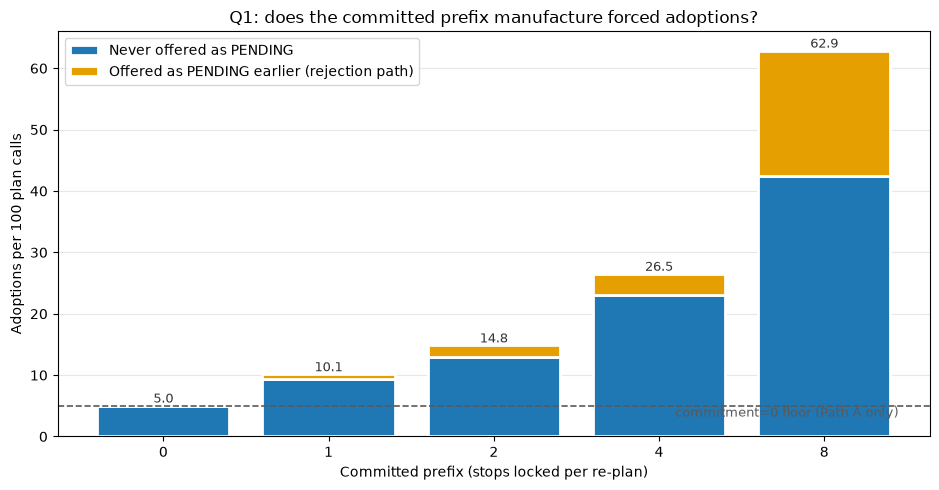

In [6]:
# Two-colour categorical pair, validated for CVD separation (worst adjacent
# dE 28.0 under protanopia). Values are labelled directly, which is also the
# relief the amber needs against a light page.
UNSEEN_COLOUR = "#1f77b4"
SEEN_COLOUR = "#e69f00"

positions = list(range(len(COMMITMENTS)))
unseen = [per_100(t.adoptions_unseen, t.plan_calls) for t in TALLIES]
seen = [per_100(seen_adoptions(t), t.plan_calls) for t in TALLIES]
totals = [u + s for u, s in zip(unseen, seen)]

fig, ax = plt.subplots(figsize=(9.5, 5))
ax.bar(positions, unseen, color=UNSEEN_COLOUR, edgecolor="white",
       linewidth=2, label="Never offered as PENDING")
ax.bar(positions, seen, bottom=unseen, color=SEEN_COLOUR,
       edgecolor="white", linewidth=2,
       label="Offered as PENDING earlier (rejection path)")

# Path A alone: at commitment=0 the projection loop never runs, so nothing
# above this line can be blamed on anything but the committed prefix.
ax.axhline(totals[0], color="0.35", linestyle="--", linewidth=1.2)
ax.annotate("commitment=0 floor (Path A only)",
            xy=(positions[-1] + 0.45, totals[0]),
            ha="right", va="top", fontsize=9, color="0.35")

for position, total in zip(positions, totals):
    ax.text(position, total, f"{total:.1f}", ha="center", va="bottom",
            fontsize=9, color="0.2")

ax.set_xticks(positions)
ax.set_xticklabels([str(c) for c in COMMITMENTS])
ax.set_xlabel("Committed prefix (stops locked per re-plan)")
# Several unscheduled riders can board at one stop, so this is a rate per 100
# calls rather than a bounded share.
ax.set_ylabel("Adoptions per 100 plan calls")
ax.set_title("Q1: does the committed prefix manufacture forced adoptions?")
ax.grid(True, axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

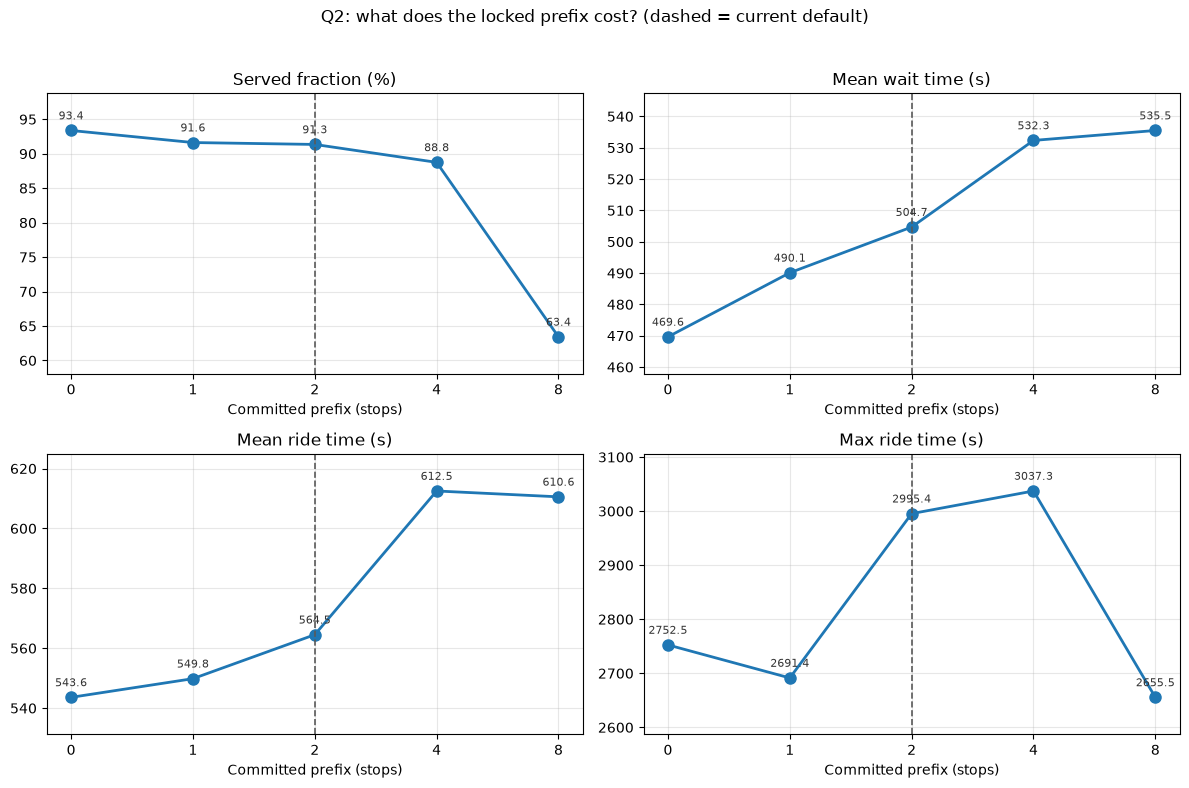

In [7]:
def kpi_mean(commitment: int, field_name: str) -> float:
    """
    Mean of one KPISnapshot field across the trials at one level.
    :param commitment: Commitment level selecting the column.
    :param field_name: Attribute name on KPISnapshot.
    :return: The mean across trials, or NaN when no trial defined it.
    """
    trials = summaries[commitment].results[commitment_label(commitment)]
    values = [
        value for trial in trials
        if (value := getattr(trial.kpi, field_name)) is not None
    ]
    return statistics.fmean(values) if values else float("nan")


def mean_max_ride(commitment: int) -> float:
    """
    Mean across trials of each trial's longest ride.

    KPISnapshot carries no max-ride field, so this is derived from
    ``ride_times`` the same way the summary table's "Max ride time" row is.
    :param commitment: Commitment level selecting the column.
    :return: Mean per-trial maximum ride time in seconds, or NaN.
    """
    trials = summaries[commitment].results[commitment_label(commitment)]
    maxima = [max(t.ride_times) for t in trials if t.ride_times]
    return statistics.fmean(maxima) if maxima else float("nan")


PANELS: list[tuple[str, Callable[[int], float]]] = [
    ("Served fraction (%)",
     lambda c: 100.0 * kpi_mean(c, "served_fraction")),
    ("Mean wait time (s)", lambda c: kpi_mean(c, "mean_wait_time")),
    ("Mean ride time (s)", lambda c: kpi_mean(c, "mean_ride_time")),
    ("Max ride time (s)", mean_max_ride),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (title, extract) in zip(axes.ravel(), PANELS):
    values = [extract(commitment) for commitment in COMMITMENTS]
    ax.plot(positions, values, "-o", color=UNSEEN_COLOUR, linewidth=2,
            markersize=8)
    # The current default, so any proposed change reads against it.
    ax.axvline(COMMITMENTS.index(2), color="0.35", linestyle="--",
               linewidth=1.2)
    for position, value in zip(positions, values):
        ax.annotate(f"{value:.1f}", xy=(position, value),
                    xytext=(0, 8), textcoords="offset points",
                    ha="center", fontsize=8, color="0.2")
    ax.set_xticks(positions)
    ax.set_xticklabels([str(c) for c in COMMITMENTS])
    ax.set_xlabel("Committed prefix (stops)")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.margins(y=0.18)

fig.suptitle("Q2: what does the locked prefix cost? (dashed = current "
             "default)")
fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.96))
plt.show()

## 6. KPI tables

One table per level, for the rows the four panels above leave out. The
`commitment=2` table is the one to check against the headroom notebook.

In [8]:
for commitment in COMMITMENTS:
    display(Markdown(
        f"**{commitment_label(commitment)}**\n\n"
        + summaries[commitment].markdown
    ))

**commitment=0**

| Property | commitment=0 |
| --- | --- |
| Fulfilled requests | 186.8 (±0.9%) |
| Cancelled requests | 13.2 (±12.5%) |
| Mean wait time | 469.6 s (±2.3%) |
| P90 wait time | 856.2 s (±0.5%) |
| Mean ride time | 543.6 s (±4.2%) |
| Fulfillment rate | 93.4 % (±0.9%) |
| Served fraction | 93.4 % (±0.9%) |
| Throughput | 0.8 req/min (±1.3%) |
| Tick snapshots | 13207.5 (±0.8%) |
| Fulfilled (wait samples) | 186.8 (±0.9%) |
| Min wait time | 5.1 s (±63.1%) |
| Max wait time | 897.2 s (±0.1%) |
| Min ride time | 5.7 s (±23.3%) |
| Max ride time | 2752.5 s (±8.9%) |

**commitment=1**

| Property | commitment=1 |
| --- | --- |
| Fulfilled requests | 183.2 (±0.9%) |
| Cancelled requests | 16.8 (±9.5%) |
| Mean wait time | 490.1 s (±1.5%) |
| P90 wait time | 857.2 s (±0.7%) |
| Mean ride time | 549.8 s (±5.8%) |
| Fulfillment rate | 91.6 % (±0.9%) |
| Served fraction | 91.6 % (±0.9%) |
| Throughput | 0.8 req/min (±1.3%) |
| Tick snapshots | 13238.1 (±0.8%) |
| Fulfilled (wait samples) | 183.2 (±0.9%) |
| Min wait time | 6.9 s (±52.4%) |
| Max wait time | 897.2 s (±0.1%) |
| Min ride time | 6.5 s (±24.4%) |
| Max ride time | 2691.4 s (±9.4%) |

**commitment=2**

| Property | commitment=2 |
| --- | --- |
| Fulfilled requests | 182.7 (±1.3%) |
| Cancelled requests | 17.3 (±13.2%) |
| Mean wait time | 504.7 s (±2.1%) |
| P90 wait time | 858.0 s (±0.5%) |
| Mean ride time | 564.5 s (±5.2%) |
| Fulfillment rate | 91.3 % (±1.3%) |
| Served fraction | 91.3 % (±1.3%) |
| Throughput | 0.8 req/min (±1.5%) |
| Tick snapshots | 13254.0 (±0.5%) |
| Fulfilled (wait samples) | 182.7 (±1.3%) |
| Min wait time | 6.3 s (±49.6%) |
| Max wait time | 897.1 s (±0.1%) |
| Min ride time | 6.6 s (±30.1%) |
| Max ride time | 2995.4 s (±9.8%) |

**commitment=4**

| Property | commitment=4 |
| --- | --- |
| Fulfilled requests | 177.5 (±1.9%) |
| Cancelled requests | 22.5 (±14.7%) |
| Mean wait time | 532.3 s (±1.9%) |
| P90 wait time | 865.5 s (±0.6%) |
| Mean ride time | 612.5 s (±6.3%) |
| Fulfillment rate | 88.8 % (±1.9%) |
| Served fraction | 88.8 % (±1.9%) |
| Throughput | 0.8 req/min (±2.3%) |
| Tick snapshots | 13205.6 (±0.9%) |
| Fulfilled (wait samples) | 177.5 (±1.9%) |
| Min wait time | 5.2 s (±45.3%) |
| Max wait time | 897.8 s (±0.1%) |
| Min ride time | 7.4 s (±28.7%) |
| Max ride time | 3037.3 s (±11.3%) |

**commitment=8**

| Property | commitment=8 |
| --- | --- |
| Fulfilled requests | 126.8 (±5.7%) |
| Cancelled requests | 73.2 (±10.0%) |
| Mean wait time | 535.5 s (±1.8%) |
| P90 wait time | 864.6 s (±0.5%) |
| Mean ride time | 610.6 s (±3.9%) |
| Fulfillment rate | 63.4 % (±5.7%) |
| Served fraction | 63.4 % (±5.7%) |
| Throughput | 0.6 req/min (±5.9%) |
| Tick snapshots | 13219.0 (±0.8%) |
| Fulfilled (wait samples) | 126.8 (±5.7%) |
| Min wait time | 10.2 s (±51.6%) |
| Max wait time | 896.6 s (±0.1%) |
| Min ride time | 11.9 s (±33.1%) |
| Max ride time | 2655.5 s (±14.5%) |

## What to look for

**Q1 — the stacked bar.** Compare every level against the `commitment=0`
floor.

- *Totals rise with commitment* → Path B confirmed. The committed prefix is
  taking pending requests away from the policy before it can schedule them,
  and the excess over the floor is the count. Lowering `commitment` then
  removes those forced adoptions outright, and the reordering work inherits a
  cleaner schedule for free.
- *Totals flat* → Path B contributes nothing measurable. Adoption is the
  arrival-then-replan ordering in `BusAgent.on_arrival`, which no parameter
  reaches. The honest conclusion is that ~15% of riders will always arrive as
  dropoff-only obligations, and `_adopt_dropoff` deserves to be treated as a
  first-class part of the design rather than an edge case — including a
  feasibility check it currently does not have.
- *The amber segment grows with commitment* → unexpected, and it would mean
  a longer prefix causes more rejections rather than more pre-boarding. Read
  the "rejected attempts" row before believing it.

**Q2 — the four panels.** The dashed line marks the current default.

- *Served fraction highest at 0 or 1* → lower the default. Free coverage, no
  new code. Confirm it survives at 500 requests before changing anything.
- *Flat within the confidence intervals in section 6* → commitment is
  KPI-neutral here; keep 2, since CARLA needs a non-zero prefix and there is
  no measured reason to prefer another value.
- *Max ride climbing with commitment* → the staler projection is degrading
  ride quality specifically, which would matter because ride tail is where
  reordering is expected to pay off. Two effects in the same place would need
  disentangling before L1 results could be read cleanly.

**The regression check comes first.** If `commitment=2` does not reproduce
3,862 plan calls / 14.8 adoptions / 91.3% served, stop and work out why before
reading anything else on the page.

### A caveat on reproducibility

Set `PYTHONHASHSEED=0` before launching Jupyter. Python randomizes string
hashing per process and several policies break ties with `min()` over a
`set[str]`; the regression check above is only meaningful with it fixed.

### Follow-ups this could trigger

```python
# Does a lower commitment still win under heavier demand?
summary_heavy = summarize_comparison(
    policies=[("commitment=0", make_factory("c0 heavy", 900.0))],
    graph=graph, n_trials=20, base_seed=0,
    max_requests=500, capacity=40, max_wait_s=900.0, commitment=0,
)

# Does commitment matter at all without a window binding?
summary_ablation = summarize_comparison(
    policies=[("no window, c=0", make_factory("nw c0", 1e9))],
    graph=graph, n_trials=20, base_seed=0, commitment=0, **LOAD,
)
```